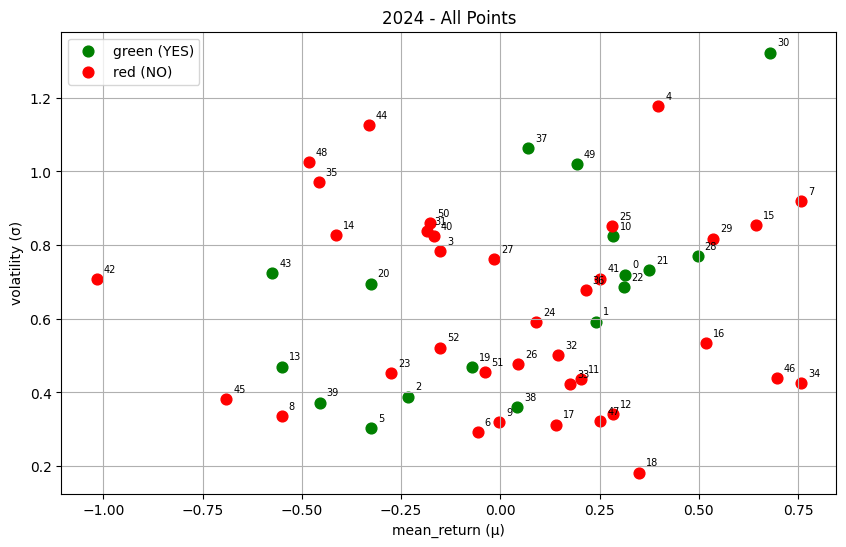

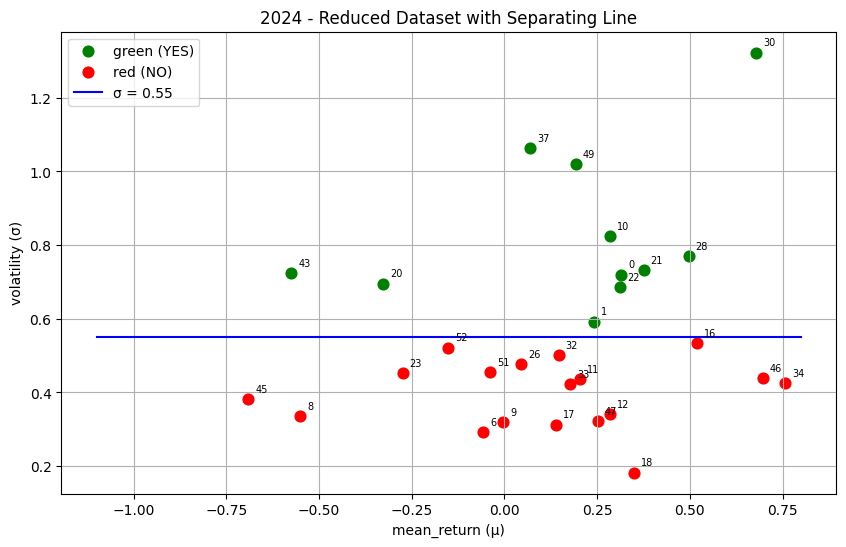

Line equation: σ = 0.55
Reduced dataset: 29 weeks (removed 24)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('KO_weekly_return_volatility.csv')
df['color'] = df['decision'].apply(lambda x: 'green' if x == 'YES' else 'red')

year1 = df[df['Year'] == 2024].copy()
year2 = df[df['Year'] == 2025].copy()

# plot 2024 - µ vs σ colored by label
green = year1[year1['color'] == 'green']
red   = year1[year1['color'] == 'red']

plt.figure(figsize=(10, 6))
plt.scatter(green['mean_return'], green['volatility'], c='green', s=60, label='green (YES)')
plt.scatter(red['mean_return'],   red['volatility'],   c='red',   s=60, label='red (NO)')
for _, row in year1.iterrows():
    plt.annotate(str(int(row['Week_Number'])),
                 (row['mean_return'], row['volatility']),
                 textcoords="offset points", xytext=(5, 5), fontsize=7)
plt.xlabel('mean_return (µ)')
plt.ylabel('volatility (σ)')
plt.title('2024 - All Points')
plt.legend()
plt.grid(True)
plt.savefig('2024_all.pdf', bbox_inches='tight')
plt.show()

# horizontal line at σ = 0.55
# above the line = green, below = red
# removing points that fall on the wrong side
weeks_to_remove = [2, 3, 4, 5, 7, 13, 14, 15, 19, 24, 25, 27,
                   29, 31, 35, 36, 38, 39, 40, 41, 42, 44, 48, 50]

reduced = year1[~year1['Week_Number'].isin(weeks_to_remove)].copy()

# plot reduced dataset with the separating line
green_r = reduced[reduced['color'] == 'green']
red_r   = reduced[reduced['color'] == 'red']

x_line = np.linspace(-1.1, 0.8, 100)
y_line = np.full_like(x_line, 0.55)  # horizontal line σ = 0.55

plt.figure(figsize=(10, 6))
plt.scatter(green_r['mean_return'], green_r['volatility'], c='green', s=60, label='green (YES)')
plt.scatter(red_r['mean_return'],   red_r['volatility'],   c='red',   s=60, label='red (NO)')
plt.plot(x_line, y_line, 'b-', label='σ = 0.55')
for _, row in reduced.iterrows():
    plt.annotate(str(int(row['Week_Number'])),
                 (row['mean_return'], row['volatility']),
                 textcoords="offset points", xytext=(5, 5), fontsize=7)
plt.xlabel('mean_return (µ)')
plt.ylabel('volatility (σ)')
plt.title('2024 - Reduced Dataset with Separating Line')
plt.legend()
plt.grid(True)
plt.savefig('2024_reduced.pdf', bbox_inches='tight')
plt.show()

print(f"Line equation: σ = 0.55")
print(f"Reduced dataset: {len(reduced)} weeks (removed {len(weeks_to_remove)})")

In [4]:
# apply line to 2025 - above σ = 0.55 = green, below = red
year2 = year2.copy()
year2['predicted_color'] = year2['volatility'].apply(lambda x: 'green' if x >= 0.55 else 'red')

print(f"\n2025 predicted labels:")
print(f"Green: {(year2['predicted_color']=='green').sum()}, Red: {(year2['predicted_color']=='red').sum()}")
year2.to_csv('2025_predicted_labels.csv', index=False)


2025 predicted labels:
Green: 43, Red: 10


In [5]:
# trading strategy - buy on green weeks, skip red weeks
capital = 100.0

for _, row in year2.iterrows():
    if row['predicted_color'] == 'green':
        capital = capital * (1 + row['mean_return'] / 100)

print(f"Final capital: ${round(capital, 2)}")

Final capital: $104.06
